# Conditions check — can this data be normalised and correlated?

Beamtime goal 1 (see `CLAUDE.md`): before trusting any normalisation or
covariance, check per run that

- the **machine** is stable (pulse energy, pulses per train, photon energy, beam position, shutter),
- the **VLS** is lined up with the FEL pulses, not saturated, and usable as a single-shot photon-energy / intensity monitor,
- the **TDC hit finder** is not saturated (hits per bunch hitting the `max_ecounts` / `max_icounts` cap), dead time / double counting is under control, and the **detectors** respond linearly to pulse energy,
- electrons, ions, GMD and VLS **correlate** as expected and the normalised yields don't drift.

**Two modes** (set in the parameter cell):

| `COMBINED_H5` | Data | Sections that run |
|---|---|---|
| `None` | raw FLASH files of `RUN` (`load_raw_h5`) | machine, GMD, OPIS, VLS |
| path | combined file from `write_h5.py` (`load_data`) | everything, incl. electron / ion TOF |

Everything is kept as plain numpy arrays at the top level (`gmd`, `vls`, `n_e`, `vls_sum`, …, all shaped
`(n_trains, n_bunches)` or with an extra last axis) and each plot cell builds its own figure — edit freely.
Sections that need data the run doesn't have print a note and skip.

In [1]:
# ---- Parameters ---------------------------------------------------------------
RUN = 60538            # FLASH run (raw mode; also the run used for extra raw channels)
COMBINED_H5 = 'run60538_Argon_2807259185.h5'          # combined file from write_h5.py, e.g. "energy_scan1.h5" (relative to
                       # config.COMBINED_DIR) or an absolute path; None = raw FLASH files only (no TOF)
TRAIN_STEP = 20        # use every N-th train — the VLS costs ~0.5 MB per train
MAX_FILES = None       # raw mode: read only the first N raw files of the run

# Bunch slots used as "shots" for per-shot statistics: (start, stop), half-open.
# None = every slot where the GMD shows a pulse in most trains (set in section 3).
BUNCH_RANGE = None

# VLS (Gotthard). Pixel ranges are half-open.
VLS_OFFSET = None            # raw mode: Gotthard line b+offset -> bunch b; None = config.VLS_OFFSET
VLS_ROI = (480, 640)         # pixels holding the spectrum — moves with photon energy, check section 6
VLS_BG_PIXELS = (650, 800)   # signal-free pixels: per-shot common-mode offset
# Set to NaN on load: 0-1 stuck at 51914, 679-681 hot, 832-863 a dead block (flat ~4790 ADU, no noise)
VLS_BAD_PIXELS = [0, 1, 679, 680, 681, *range(832, 864)]
VLS_SATURATION = 51914       # ADU; highest raw value seen so far (where pixels 0-1 sit)

# TOF (combined mode), in ns: tofs_e / tofs_i are converted on load from the TDC units (100 ps) in the files.
# One bunch period is ~3988 ns. Electron hits after ~1000 ns include crosstalk from the ion spectrometer (a hit
# ~25 ns after each ion hit), so the electron windows stop there. Add windows for individual peaks,
# e.g. {"all e": (0, 1000), "peak": (85, 110)}.
E_TOF_WINDOWS = {"all e": (0, 1000)}
I_TOF_WINDOWS = {"all ions": (0, 4000)}
E_TOF_RANGE = (0, 1000)      # ns shown in the electron spectra and per-slot maps
I_TOF_RANGE = (0, 4000)      # ns shown in the ion spectra and per-slot maps
TOF_BIN = 2                  # ns per bin in the average TOF spectra
MAP_TOF_BIN = 10             # ns per bin in the per-slot maps (each slot only has n_trains shots)
TOF_MAP_NORM = "gmd"         # normalised per-slot maps: "gmd" = sum(hits) / sum(GMD); "area" = each slot / its own sum
N_GMD_BINS = 20              # pulse-energy bins for the linearity plots

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Empty bunch slots are NaN by design, so these numpy warnings are expected noise
for msg in ("All-NaN slice", "Mean of empty slice", "invalid value encountered", "divide by zero",
            "Degrees of freedom"):
    warnings.filterwarnings("ignore", message=msg)

# Repo root = the first folder above the working directory that holds analysis/scripts/config.py
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
import data_loading

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TRAIN_RATE_HZ = 10           # FLASH train rate — for time axes
TDC_PER_NS = 10              # TDC units (100 ps) per ns
if VLS_OFFSET is None:
    VLS_OFFSET = config.VLS_OFFSET
print("beamtime", config.BEAMTIME_ID, "| data root:", config.DATA_ROOT)

beamtime 11024642 | data root: /home/ogalex/gas-vls/11024642


## 1. Load

Raw mode reads GMD, OPIS photon energy, shutter and (if the run has it) the VLS straight from the
FLASH files, every `TRAIN_STEP`-th train. Combined mode reads the `write_h5.py` output, which adds the
electron / ion TOF hits (`tofs_e`, `tofs_i`: zero-padded, one row of hits per bunch slot, in ns).

In [3]:
if COMBINED_H5 is None:
    data = data_loading.load_raw_h5(RUN, config=1, train_step=TRAIN_STEP, max_files=MAX_FILES,
                                    vls_offset=VLS_OFFSET)
    source = f"run {RUN} (raw, every {TRAIN_STEP}. train)"
else:
    h5_path = Path(COMBINED_H5)
    if not h5_path.is_absolute():
        h5_path = config.COMBINED_DIR / h5_path
    data = data_loading.load_data(str(h5_path), config=1, downsample_N=TRAIN_STEP)
    source = f"{h5_path.name} (every {TRAIN_STEP}. train)"
    with h5py.File(h5_path, "r") as f:
        if "vls" in f:                       # the offset the file was written with
            VLS_OFFSET = int(f["vls"].attrs.get("vls_offset", VLS_OFFSET))

# Plain arrays — use these directly
tID     = data.tID        # (n_trains,)
gmd     = data.gmd        # (n_trains, n_bunches)   µJ, NaN = no pulse in that slot
mpe     = data.mpe        # (n_trains,)             eV, OPIS; NaN where it didn't update
shutter = data.shutter    # (n_trains,) or None
vls     = data.vls        # (n_trains, n_bunches, 1280) float32 ADU, NaN = no Gotthard line; or None
# TOF hits in ns (float32; the files hold TDC units of 100 ps), 0 = padding; or None
to_ns = lambda t: None if t is None else t.astype(np.float32) / np.float32(TDC_PER_NS)
tofs_e  = to_ns(data.tofs_e)   # (n_trains, n_bunches, max_ecounts)
tofs_i  = to_ns(data.tofs_i)   # (n_trains, n_bunches, max_icounts)

n_trains, n_bunches = gmd.shape
t_min = (tID - tID[0]) / TRAIN_RATE_HZ / 60    # minutes since the first train
if vls is not None:
    vls[..., VLS_BAD_PIXELS] = np.nan          # mask stuck pixels in place

print(source)
print(f"{n_trains} trains x {n_bunches} bunch slots | VLS: {vls is not None} "
      f"(line b+{VLS_OFFSET} -> bunch b) | TOF: {tofs_e is not None}")

run60538_Argon_2807259185.h5 (every 20. train)
303 trains x 101 bunch slots | VLS: False (line b+10 -> bunch b) | TOF: True


**Any other raw channel.** `read_raw(key)` returns `(train_ids, values)` for one raw-H5 group (the path
without `/index` / `/value`) over all files of `RUN`; `on_trains(...)` puts it on this notebook's train
axis (NaN where the channel has no entry). Used here for the beam position; try e.g. the electron bunch
charge `"/FL1/Electron Diagnostic/Bunch charge/at gun"` or the GMD tunnel
`"/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy tunnel"`.

In [4]:
def read_raw(key, run=RUN):
    # (train_ids, values) of one raw-H5 group over all files of a run; file-boundary duplicates dropped
    tids, vals = [], []
    for p in sorted(config.RAW_H5_DIR.glob(f"*run{run}_*.h5")):
        with h5py.File(p, "r") as f:
            if key + "/value" in f:
                tids.append(f[key + "/index"][:])
                vals.append(f[key + "/value"][:])
    if not tids:
        print(f"{key}: not in run {run}")
        return np.array([]), np.array([])
    tids, vals = np.concatenate(tids), np.concatenate(vals)
    tids, first = np.unique(tids, return_index=True)
    return tids, vals[first]


def on_trains(src_tid, src_val, tid=tID):
    # values of a channel on our train axis; NaN where the channel has no entry for a train
    out = np.full((len(tid),) + np.shape(src_val)[1:], np.nan)
    if len(src_tid) == 0:
        return out
    pos = np.clip(np.searchsorted(src_tid, tid), 0, len(src_tid) - 1)
    hit = src_tid[pos] == tid
    out[hit] = src_val[pos[hit]]
    return out


if COMBINED_H5 is None:
    hor_pos = on_trains(*read_raw("/FL2/Photon Diagnostic/GMD/Average beam position/position hall horizontal"))
    ver_pos = on_trains(*read_raw("/FL2/Photon Diagnostic/GMD/Average beam position/position hall vertical"))
else:                                    # the combined file carries them already
    with h5py.File(h5_path, "r") as f:
        hor_pos = on_trains(f["tID"][:], f["hor_pos"][:])
        ver_pos = on_trains(f["tID"][:], f["ver_pos"][:])
print(f"beam position on {100 * np.isfinite(hor_pos).mean():.0f}% of trains (it updates ~1 Hz)")

beam position on 0% of trains (it updates ~1 Hz)


## 2. Run overview — is the machine stable?

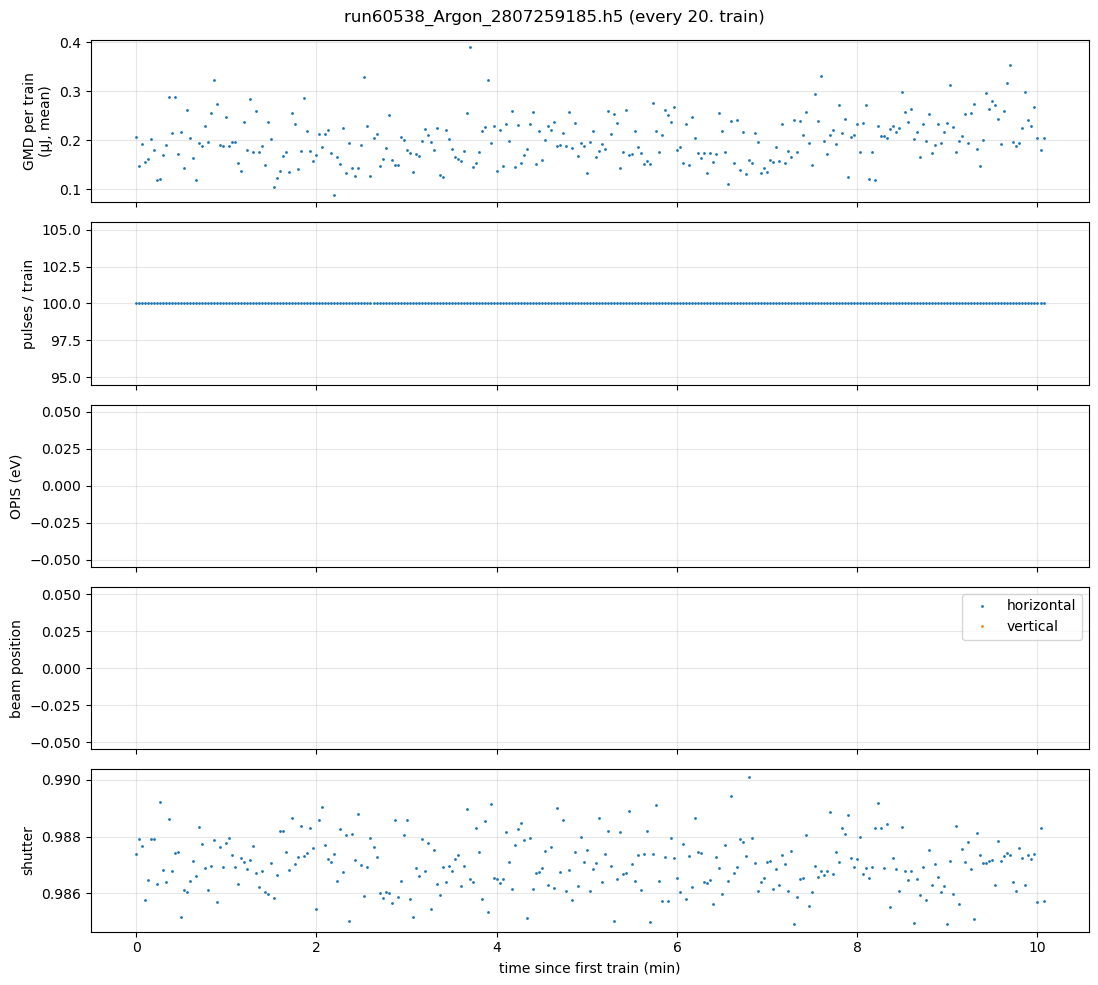

In [5]:
gmd_train = np.nanmean(gmd, axis=1)        # mean pulse energy per train
n_pulses = np.isfinite(gmd).sum(axis=1)    # pulses per train

fig, axs = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
axs[0].plot(t_min, gmd_train, ".", ms=2)
axs[0].set_ylabel("GMD per train\n(µJ, mean)")
axs[1].plot(t_min, n_pulses, ".", ms=2)
axs[1].set_ylabel("pulses / train")
ok = np.isfinite(mpe) & (mpe > 0)
axs[2].plot(t_min[ok], mpe[ok], ".", ms=2)
axs[2].set_ylabel("OPIS (eV)")
axs[3].plot(t_min, hor_pos, ".", ms=2, label="horizontal")
axs[3].plot(t_min, ver_pos, ".", ms=2, label="vertical")
axs[3].set_ylabel("beam position")
axs[3].legend(loc="upper right")
if shutter is not None:
    axs[4].plot(t_min, shutter, ".", ms=2)
axs[4].set_ylabel("shutter")
axs[4].set_xlabel("time since first train (min)")
fig.suptitle(source)
fig.tight_layout()
plt.show()

## 3. Bunch pattern — which slots carry pulses?

Defines the shots used from here on: `shot[train, slot]` is True where the slot is inside `BUNCH_RANGE`
and the GMD recorded a pulse. Set `BUNCH_RANGE` in the parameter cell to override.

BUNCH_RANGE = (0, 100) (100 slots) -> 30300 shots


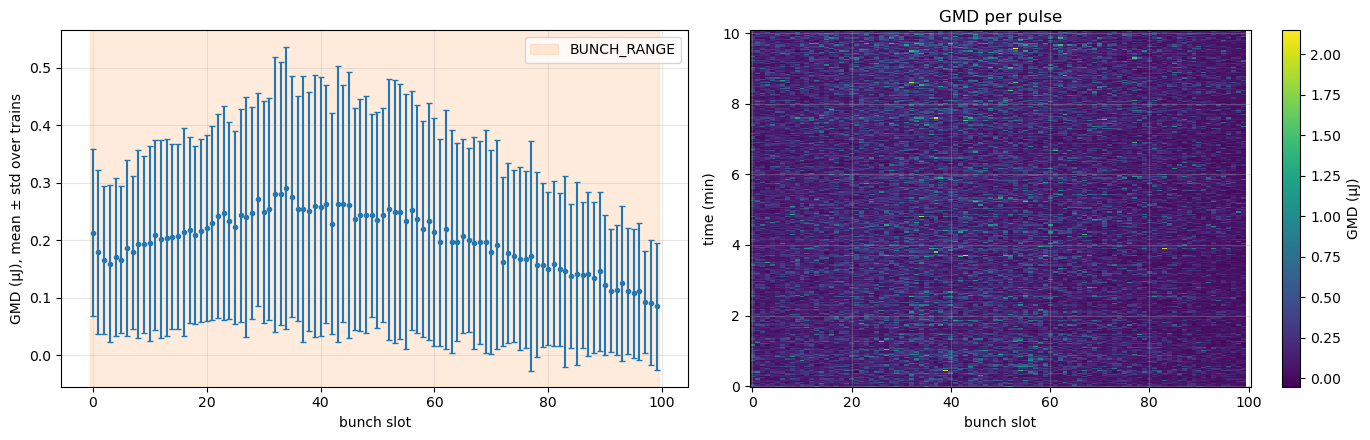

In [6]:
pulse = np.isfinite(gmd)                    # (n_trains, n_bunches) GMD saw a pulse
pulse_frac = pulse.mean(axis=0)             # fraction of trains with a pulse, per slot
if BUNCH_RANGE is None:
    lit_slots = np.flatnonzero(pulse_frac > 0.5)
    BUNCH_RANGE = (int(lit_slots[0]), int(lit_slots[-1]) + 1)
b0, b1 = BUNCH_RANGE
shot = np.zeros_like(pulse)
shot[:, b0:b1] = pulse[:, b0:b1]
print(f"BUNCH_RANGE = {BUNCH_RANGE} ({b1 - b0} slots) -> {shot.sum()} shots")

slots = np.arange(n_bunches)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].errorbar(slots, np.nanmean(gmd, axis=0), np.nanstd(gmd, axis=0), fmt=".", capsize=2)
axs[0].axvspan(b0 - 0.5, b1 - 0.5, color="C1", alpha=0.15, label="BUNCH_RANGE")
axs[0].set(xlabel="bunch slot", ylabel="GMD (µJ), mean ± std over trains")
axs[0].legend()
mesh = axs[1].pcolormesh(slots, t_min, gmd, shading="nearest", cmap="viridis")
fig.colorbar(mesh, ax=axs[1], label="GMD (µJ)")
axs[1].set(xlabel="bunch slot", ylabel="time (min)", title="GMD per pulse")
fig.tight_layout()
plt.show()

## 4. Pulse energy and photon energy

GMD per shot: mean 0.20 µJ, std 0.18 µJ (91%), 1-99% 0.00-0.87 µJ, 30300 shots
OPIS: no photon-energy values in this data


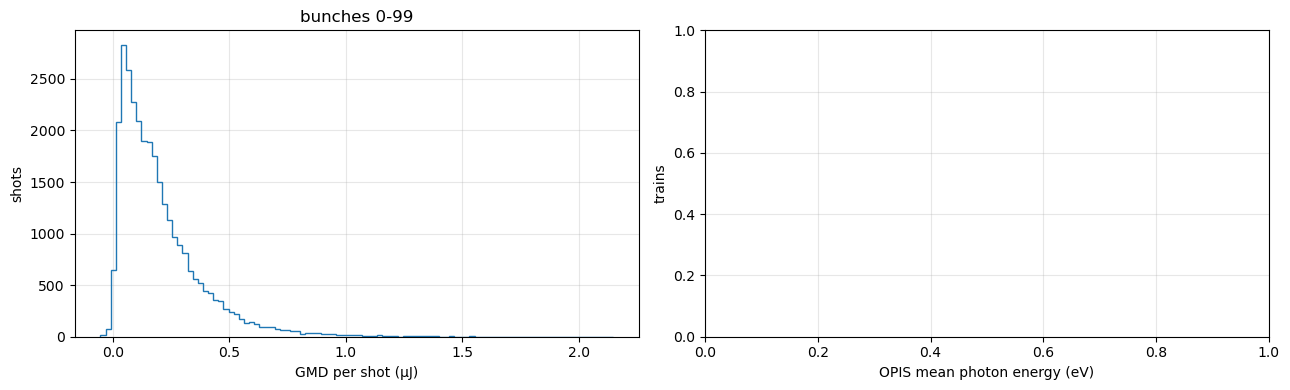

In [7]:
g = gmd[shot]                                    # pulse energy of every shot (1-D)
print(f"GMD per shot: mean {g.mean():.2f} µJ, std {g.std():.2f} µJ ({100 * g.std() / g.mean():.0f}%), "
      f"1-99% {np.percentile(g, 1):.2f}-{np.percentile(g, 99):.2f} µJ, {g.size} shots")
ok = np.isfinite(mpe) & (mpe > 0)
if ok.any():
    print(f"OPIS: value on {100 * ok.mean():.0f}% of trains, mean {mpe[ok].mean():.2f} eV, "
          f"std {mpe[ok].std():.3f} eV")
else:
    print("OPIS: no photon-energy values in this data")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].hist(g, bins=100, histtype="step")
axs[0].set(xlabel="GMD per shot (µJ)", ylabel="shots", title=f"bunches {b0}-{b1 - 1}")
if ok.any():
    axs[1].hist(mpe[ok], bins=60, histtype="step")
axs[1].set(xlabel="OPIS mean photon energy (eV)", ylabel="trains")
fig.tight_layout()
plt.show()

## 5. VLS — frames, pedestal and saturation

Each bunch slot holds one Gotthard line (NaN where there is none). Lines in slots **without** an FEL pulse
are dark frames: their per-pixel mean is the pedestal. Check that `VLS_ROI` covers the spectrum and
`VLS_BG_PIXELS` is signal-free — the spectrum moves with photon energy.

In [8]:
if vls is None:
    print("No VLS in this data — VLS sections are skipped.")
else:
    has_frame = np.isfinite(vls[:, :, VLS_BG_PIXELS[0]])   # (n_trains, n_bunches) slot holds a Gotthard line
    dark = has_frame & ~pulse                              # line but no FEL pulse
    lit = has_frame & pulse

    def frame_mean(mask):
        # mean frame (per pixel) over the (train, slot) positions where mask is True
        total, n = np.zeros(vls.shape[-1]), 0
        for b in np.flatnonzero(mask.any(axis=0)):
            rows = mask[:, b]
            total += vls[rows, b].sum(axis=0)
            n += rows.sum()
        return total / max(n, 1)

    mean_lit = frame_mean(lit)
    if dark.sum() > 100:
        pedestal = frame_mean(dark)
    else:
        pedestal = np.zeros(vls.shape[-1])
        print("WARNING: (almost) no dark frames — no per-pixel pedestal; relying on the common-mode subtraction")
    print(f"slots with a line: {has_frame.any(axis=0).sum()} | lit shots: {lit.sum()} | dark frames: {dark.sum()}")

    px = np.arange(vls.shape[-1])
    fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axs[0].plot(px, mean_lit, lw=0.8, label="mean lit frame")
    axs[0].plot(px, pedestal, lw=0.8, label="pedestal (mean dark frame)")
    axs[0].set_ylabel("ADU")
    axs[1].plot(px, mean_lit - pedestal, lw=0.8)
    axs[1].set(xlabel="pixel", ylabel="lit − pedestal (ADU)")
    for ax in axs:
        ax.axvspan(*VLS_ROI, color="C2", alpha=0.15, label="VLS_ROI")
        ax.axvspan(*VLS_BG_PIXELS, color="C7", alpha=0.2, label="VLS_BG_PIXELS")
    axs[0].legend(loc="upper right")
    fig.suptitle(f"VLS, {source}")
    fig.tight_layout()
    plt.show()

No VLS in this data — VLS sections are skipped.


Per-shot VLS quantities, all `(n_trains, n_bunches)`: `vls_sum` (ROI integral after pedestal and
common-mode subtraction), `vls_com` / `vls_width` (centre of mass / rms width in pixels, only where the
integral is above `VLS_COM_MIN`, else NaN), `vls_peak` (raw maximum ADU in the ROI) and `n_sat` (ROI
pixels at or above `VLS_SATURATION`). `spec` keeps the corrected ROI spectra
`(n_trains, n_bunches, roi_pixels)`.

In [9]:
if vls is not None:
    px_roi = np.arange(*VLS_ROI)
    spec = vls[:, :, slice(*VLS_ROI)] - pedestal[slice(*VLS_ROI)]
    common = np.nanmedian(vls[:, :, slice(*VLS_BG_PIXELS)] - pedestal[slice(*VLS_BG_PIXELS)], axis=-1)
    spec -= common[..., None]                                   # per-shot common-mode offset removed

    vls_sum = np.nansum(spec, axis=-1)
    vls_sum[~has_frame] = np.nan
    # COM / width are only meaningful with signal: require the integral above this (ADU);
    # default = 2 sigma of the dark-frame integral (or 0 without dark frames)
    VLS_COM_MIN = 2 * np.nanstd(vls_sum[dark]) if dark.sum() > 100 else 0.0
    weak = ~(vls_sum > VLS_COM_MIN)
    vls_com = np.nansum(spec * px_roi, axis=-1) / vls_sum
    vls_width = np.sqrt(np.nansum(spec * (px_roi - vls_com[..., None]) ** 2, axis=-1) / vls_sum)
    vls_com[weak] = np.nan
    vls_width[weak] = np.nan
    vls_peak = np.nanmax(vls[:, :, slice(*VLS_ROI)], axis=-1)              # raw ADU in the ROI
    n_sat = (vls[:, :, slice(*VLS_ROI)] >= VLS_SATURATION).sum(axis=-1)

    sat_frac = (n_sat[lit] > 0).mean()
    print(f"lit shots with >= 1 saturated ROI pixel: {100 * sat_frac:.2f}%  (max {n_sat.max()} in one shot) | "
          f"COM defined on {100 * np.isfinite(vls_com[lit]).mean():.0f}% of lit shots (VLS_COM_MIN = {VLS_COM_MIN:.0f})")

    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    peak_bins = np.geomspace(np.nanmin(vls_peak), max(np.nanmax(vls_peak), VLS_SATURATION) * 1.02, 300)
    axs[0].hist(vls_peak[lit], bins=peak_bins, histtype="step", label="lit")
    axs[0].hist(vls_peak[dark], bins=peak_bins, histtype="step", label="dark")
    axs[0].axvline(VLS_SATURATION, color="r", ls="--", label="VLS_SATURATION")
    axs[0].set(xlabel="max ADU in VLS_ROI per frame", ylabel="frames", yscale="log", xscale="log")
    axs[0].legend()
    # which slots see X-rays: mean VLS integral per slot vs the GMD pulse pattern
    axs[1].plot(slots, np.nanmean(vls_sum, axis=0), ".-", label="VLS ROI integral")
    ax2 = axs[1].twinx()
    ax2.plot(slots, np.nanmean(gmd, axis=0), ".-", color="C1", label="GMD")
    ax2.set_ylabel("GMD (µJ)", color="C1")
    axs[1].set(xlabel="bunch slot", ylabel="VLS ROI integral (ADU)",
               title=f"slot alignment (line b+{VLS_OFFSET} -> slot b)")
    axs[2].hist(vls_sum[lit], bins=100, histtype="step", label="lit")
    axs[2].hist(vls_sum[dark], bins=100, histtype="step", label="dark")
    axs[2].set(xlabel="VLS ROI integral (ADU)", ylabel="frames")
    axs[2].legend()
    fig.tight_layout()
    plt.show()

### Gotthard line offset

Correlation between the GMD of pulse *b* and the VLS integral of slot *b + s*, using only pulse-to-pulse
fluctuations (each slot's mean and each train's mean removed — otherwise the train-to-train intensity
jitter correlates at every shift). With the right offset the peak sits at *s* = 0; otherwise the Gotthard
line offset is `VLS_OFFSET + s` (→ `config.VLS_OFFSET`, `write_h5.py --vls-offset`).

In [10]:
if vls is not None:
    dg = gmd - np.nanmean(gmd, axis=0)              # remove each slot's mean ...
    dg -= np.nanmean(dg, axis=1, keepdims=True)     # ... and each train's mean
    dv = vls_sum - np.nanmean(vls_sum, axis=0)
    dv -= np.nanmean(dv, axis=1, keepdims=True)
    shifts = np.arange(-15, 16)
    r_shift = np.full(len(shifts), np.nan)
    for k, s in enumerate(shifts):
        b = np.arange(b0, b1)
        b = b[(b + s >= 0) & (b + s < n_bunches)]
        x, y = dg[:, b].ravel(), dv[:, b + s].ravel()
        ok = np.isfinite(x) & np.isfinite(y)
        if ok.sum() > 100:
            r_shift[k] = np.corrcoef(x[ok], y[ok])[0, 1]
    s_best = int(shifts[np.nanargmax(r_shift)])
    print(f"best s = {s_best:+d}  ->  Gotthard line offset ≈ {VLS_OFFSET + s_best} "
          f"(loaded with {VLS_OFFSET}); r = {np.nanmax(r_shift):.3f}")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(shifts, r_shift, "o-")
    ax.axvline(0, color="k", lw=0.8)
    ax.set(xlabel="slot shift s", ylabel="corr(GMD pulse b, VLS slot b+s)",
           title=f"line offset check, {source}")
    plt.show()

### VLS vs pulse energy, and the VLS as a photon-energy monitor

Left: VLS integral vs GMD per shot (detector linearity / saturation shows as curvature).
Middle: single-shot centre of mass — its spread is the single-shot photon-energy jitter (pixels; no
pixel→eV calibration yet). Right: train-averaged COM vs OPIS, for trains with an OPIS value.

In [11]:
if vls is not None:
    ok = lit & shot & np.isfinite(vls_sum)
    x, y = gmd[ok], vls_sum[ok]
    r_gv = np.corrcoef(x, y)[0, 1]
    strong = ok & np.isfinite(vls_com)                              # shots with a defined COM
    com_train = np.array([np.nanmean(c[m]) if m.any() else np.nan for c, m in zip(vls_com, strong)])
    opis = np.isfinite(mpe) & (mpe > 0) & np.isfinite(com_train)
    print(f"corr(GMD, VLS integral) = {r_gv:.3f} over {ok.sum()} shots | "
          f"single-shot COM: mean {np.nanmean(vls_com[strong]):.1f} px, std {np.nanstd(vls_com[strong]):.2f} px")

    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
    hb = axs[0].hexbin(x, y, gridsize=60, bins="log", mincnt=1)
    fig.colorbar(hb, ax=axs[0], label="shots")
    edges = np.percentile(x, np.linspace(1, 99, N_GMD_BINS + 1))
    idx = np.digitize(x, edges) - 1
    inb = (idx >= 0) & (idx < N_GMD_BINS)
    y_mean = np.bincount(idx[inb], y[inb], N_GMD_BINS) / np.bincount(idx[inb], minlength=N_GMD_BINS)
    axs[0].plot(0.5 * (edges[1:] + edges[:-1]), y_mean, "r.-", label="binned mean")
    axs[0].set(xlabel="GMD (µJ)", ylabel="VLS ROI integral (ADU)", title=f"r = {r_gv:.3f}")
    axs[0].legend()
    axs[1].hist(vls_com[strong], bins=100, histtype="step")
    axs[1].set(xlabel="VLS centre of mass (pixel)", ylabel="shots", title="single shot (integral > VLS_COM_MIN)")
    if opis.any():
        axs[2].plot(mpe[opis], com_train[opis], ".", ms=3)
    axs[2].set(xlabel="OPIS (eV)", ylabel="VLS COM, train mean (pixel)")
    fig.tight_layout()
    plt.show()

In [12]:
# Single-shot spectra: consecutive shots (waterfall) and the mean ± std spectrum in the ROI
if vls is not None:
    N_SHOW = 300
    shots_2d = spec[lit & shot][:N_SHOW]                 # (N_SHOW, roi_pixels)
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
    mesh = axs[0].pcolormesh(px_roi, np.arange(len(shots_2d)), shots_2d, shading="nearest", cmap="magma",
                             vmin=0, vmax=np.nanpercentile(shots_2d, 99.5))
    fig.colorbar(mesh, ax=axs[0], label="ADU")
    axs[0].set(xlabel="pixel", ylabel="shot #", title="single shots")
    m, sd = np.nanmean(spec[lit & shot], axis=0), np.nanstd(spec[lit & shot], axis=0)
    axs[1].plot(px_roi, m, label="mean")
    axs[1].fill_between(px_roi, m - sd, m + sd, alpha=0.3, label="± std")
    axs[1].set(xlabel="pixel", ylabel="ADU", title="ROI spectrum")
    axs[1].legend()
    fig.tight_layout()
    plt.show()

## 6. Electron / ion TOF — hit finder and detector (combined mode)

`n_e`, `n_i`: hits per bunch slot `(n_trains, n_bunches)`. A shot at the cap (`max_ecounts` /
`max_icounts`, the last axis of `tofs_e` / `tofs_i`) lost hits — the hit finder / buffer is saturated.

electrons: 4.83 hits/shot, max 38, at cap (120): 0.000% of shots, empty shots: 9.6%
ions     : 1.36 hits/shot, max 23, at cap (50): 0.000% of shots, empty shots: 41.4%


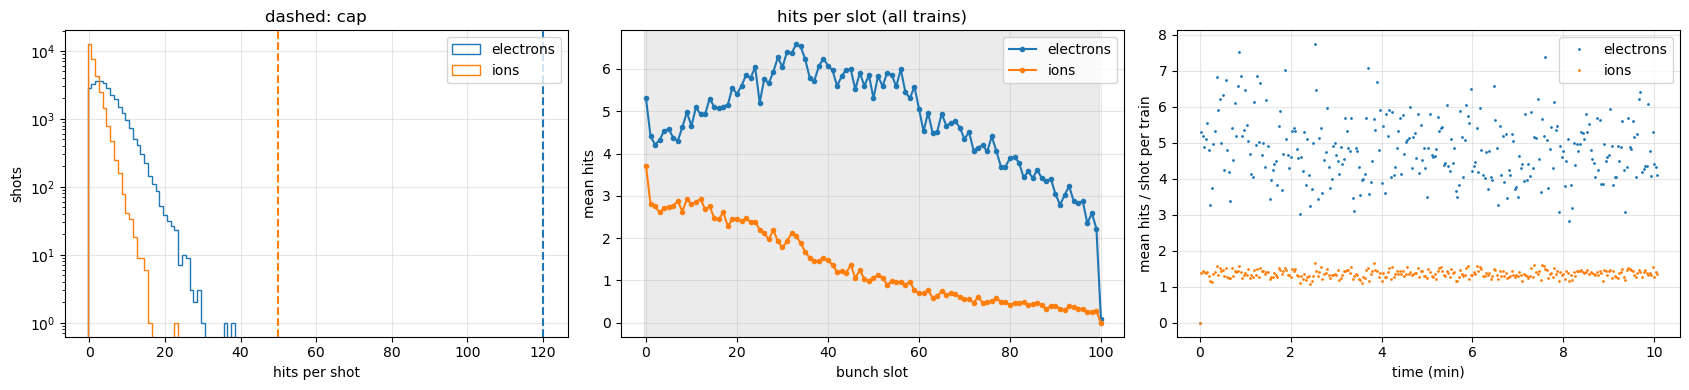

In [13]:
if tofs_e is None:
    print("No TOF data (raw mode, or no TDC files in the combined file) — TOF sections are skipped.")
else:
    n_e = (tofs_e > 0).sum(axis=-1)
    n_i = (tofs_i > 0).sum(axis=-1)
    cap_e, cap_i = tofs_e.shape[-1], tofs_i.shape[-1]
    for name, n, cap in (("electrons", n_e, cap_e), ("ions", n_i, cap_i)):
        print(f"{name:9s}: {n[shot].mean():.2f} hits/shot, max {n[shot].max()}, "
              f"at cap ({cap}): {100 * (n[shot] >= cap).mean():.3f}% of shots, "
              f"empty shots: {100 * (n[shot] == 0).mean():.1f}%")

    fig, axs = plt.subplots(1, 3, figsize=(17, 4))
    axs[0].hist(n_e[shot], bins=np.arange(cap_e + 2) - 0.5, histtype="step", label="electrons")
    axs[0].hist(n_i[shot], bins=np.arange(cap_i + 2) - 0.5, histtype="step", label="ions")
    axs[0].axvline(cap_e, color="C0", ls="--")
    axs[0].axvline(cap_i, color="C1", ls="--")
    axs[0].set(xlabel="hits per shot", ylabel="shots", yscale="log", title="dashed: cap")
    axs[0].legend()
    axs[1].plot(slots, n_e.mean(axis=0), ".-", label="electrons")
    axs[1].plot(slots, n_i.mean(axis=0), ".-", label="ions")
    axs[1].axvspan(b0 - 0.5, b1 - 0.5, color="C7", alpha=0.15)
    axs[1].set(xlabel="bunch slot", ylabel="mean hits", title="hits per slot (all trains)")
    axs[1].legend()
    axs[2].plot(t_min, np.where(shot, n_e, 0).sum(1) / np.maximum(shot.sum(1), 1), ".", ms=2, label="electrons")
    axs[2].plot(t_min, np.where(shot, n_i, 0).sum(1) / np.maximum(shot.sum(1), 1), ".", ms=2, label="ions")
    axs[2].set(xlabel="time (min)", ylabel="mean hits / shot per train")
    axs[2].legend()
    fig.tight_layout()
    plt.show()

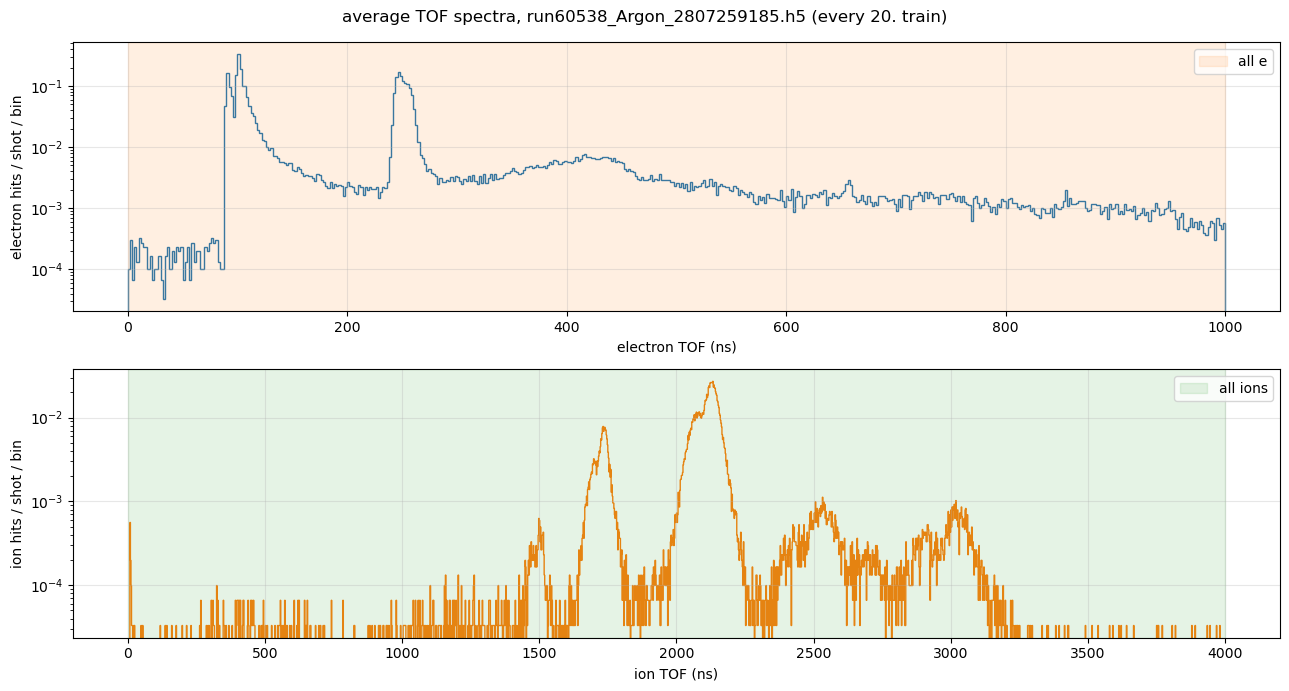

In [14]:
# Average TOF spectra (hits per shot per bin) with the count windows shaded
if tofs_e is not None:
    hits_e = tofs_e[shot]
    hits_e = hits_e[hits_e > 0]
    hits_i = tofs_i[shot]
    hits_i = hits_i[hits_i > 0]
    e_edges = np.arange(E_TOF_RANGE[0], E_TOF_RANGE[1] + TOF_BIN, TOF_BIN)   # ns
    i_edges = np.arange(I_TOF_RANGE[0], I_TOF_RANGE[1] + TOF_BIN, TOF_BIN)
    spec_e = np.histogram(hits_e, e_edges)[0] / shot.sum()
    spec_i = np.histogram(hits_i, i_edges)[0] / shot.sum()

    fig, axs = plt.subplots(2, 1, figsize=(13, 7))
    axs[0].stairs(spec_e, e_edges)
    for k, (name, (lo, hi)) in enumerate(E_TOF_WINDOWS.items()):
        axs[0].axvspan(max(lo, e_edges[0]), min(hi, e_edges[-1]), color=f"C{k + 1}", alpha=0.12, label=name)
    axs[0].set(xlabel="electron TOF (ns)", ylabel="electron hits / shot / bin", yscale="log")
    axs[0].legend(loc="upper right")
    axs[1].stairs(spec_i, i_edges, color="C1")
    for k, (name, (lo, hi)) in enumerate(I_TOF_WINDOWS.items()):
        axs[1].axvspan(max(lo, i_edges[0]), min(hi, i_edges[-1]), color=f"C{k + 2}", alpha=0.12, label=name)
    axs[1].set(xlabel="ion TOF (ns)", ylabel="ion hits / shot / bin", yscale="log")
    axs[1].legend(loc="upper right")
    fig.suptitle(f"average TOF spectra, {source}")
    fig.tight_layout()
    plt.show()

**TOF spectrum per bunch slot.** The train-averaged spectrum of every bunch slot as a TOF × slot map, for
electrons (top) and ions (bottom). Left: unnormalised, hits per train per bin over all loaded trains. Right:
normalised per `TOF_MAP_NORM`. With `"gmd"` it is `sum(hits) / sum(GMD)` over the trains with a GMD value in
that slot, so a detection efficiency that changes along the train shows as a change along the slot axis. With
`"area"` each slot is divided by its own sum, so only shape changes show. Slots without pulses are blank in the
GMD-normalised map. Dashed lines: `BUNCH_RANGE`. Log colour scale; `MAP_TOF_BIN` sets the TOF bins (a smaller
`TRAIN_STEP` gives more trains per slot and allows finer bins).

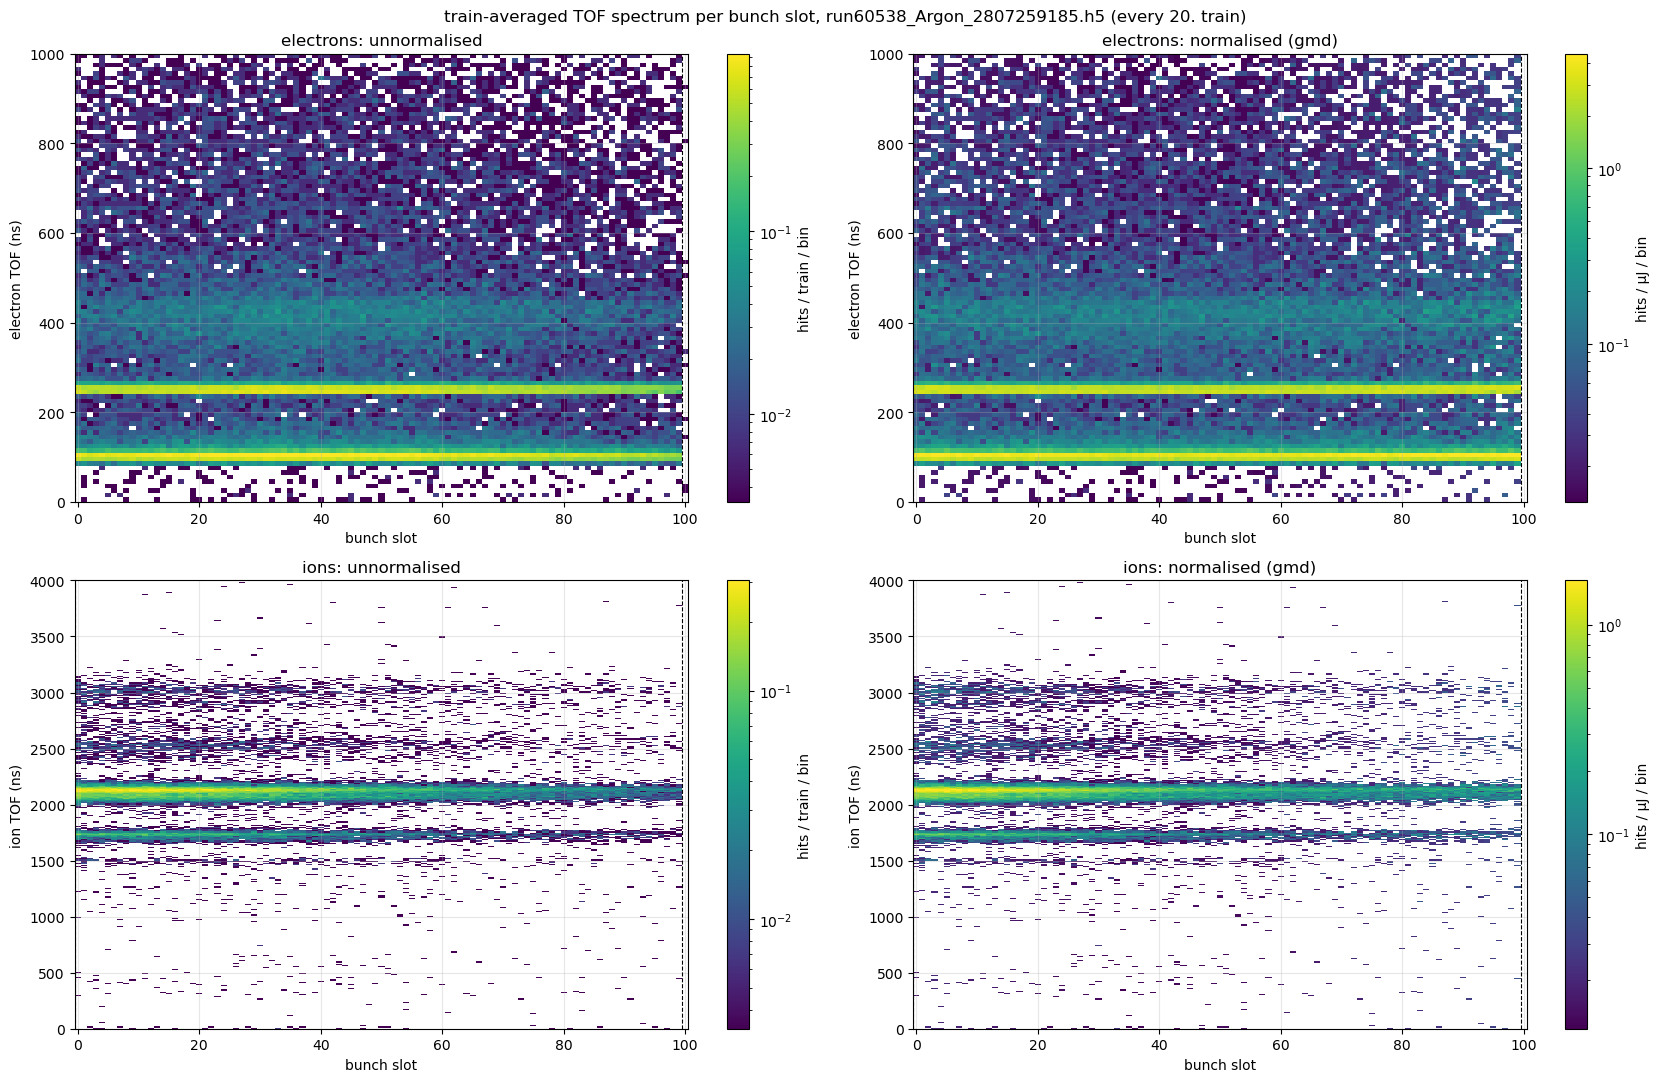

In [15]:
# Train-averaged TOF spectrum of each bunch slot: unnormalised and normalised TOF x slot maps
if tofs_e is not None:
    slot_maps = {}                                    # detector -> (tof_edges, per_train, normed), maps (n_bins, n_bunches)
    for det, tofs, (lo, hi) in (("electron", tofs_e, E_TOF_RANGE), ("ion", tofs_i, I_TOF_RANGE)):
        edges = np.arange(lo, hi + MAP_TOF_BIN, MAP_TOF_BIN)  # ns
        per_train = np.zeros((len(edges) - 1, n_bunches))
        normed = np.full((len(edges) - 1, n_bunches), np.nan)
        for b in range(n_bunches):
            t = tofs[:, b]
            per_train[:, b] = np.histogram(t[t > 0], edges)[0] / n_trains          # hits / train / bin
            has_g = np.isfinite(gmd[:, b])
            if TOF_MAP_NORM == "gmd" and has_g.any():
                t = tofs[has_g, b]
                normed[:, b] = np.histogram(t[t > 0], edges)[0] / gmd[has_g, b].sum()   # hits / µJ / bin
            elif TOF_MAP_NORM == "area" and per_train[:, b].sum() > 0:
                normed[:, b] = per_train[:, b] / per_train[:, b].sum()
        slot_maps[det] = (edges, per_train, normed)

    norm_label = {"gmd": "hits / µJ / bin", "area": "fraction of the slot's hits / bin"}[TOF_MAP_NORM]
    fig, axs = plt.subplots(2, 2, figsize=(17, 11))
    for row, (det, (edges, per_train, normed)) in enumerate(slot_maps.items()):
        for col, (M, label, title) in enumerate(((per_train, "hits / train / bin", "unnormalised"),
                                                 (normed, norm_label, f"normalised ({TOF_MAP_NORM})"))):
            ax = axs[row, col]
            pos = M[np.isfinite(M) & (M > 0)]
            norm = LogNorm(*np.percentile(pos, [1, 99.9])) if pos.size else None
            mesh = ax.pcolormesh(np.arange(n_bunches + 1) - 0.5, edges, np.where(M > 0, M, np.nan),
                                 shading="flat", cmap="viridis", norm=norm)
            fig.colorbar(mesh, ax=ax, label=label)
            for x in (b0 - 0.5, b1 - 0.5):
                ax.axvline(x, color="k", ls="--", lw=0.8)
            ax.set(xlabel="bunch slot", ylabel=f"{det} TOF (ns)", title=f"{det}s: {title}")
    fig.suptitle(f"train-averaged TOF spectrum per bunch slot, {source}")
    fig.tight_layout()
    plt.show()

**Dead time / double counting.** Spacing between consecutive hits within one shot. A hole at small
spacings is the detector + TDC dead time; a narrow peak at a fixed small spacing is ringing / double
counting of one particle.

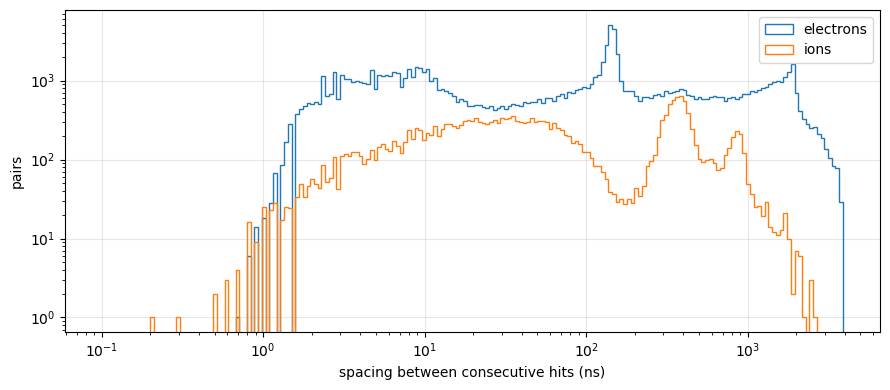

smallest spacing: electrons 0.7 ns, ions 0.2 ns


In [16]:
if tofs_e is not None:
    def hit_spacing(tofs):
        # spacing between consecutive hits of each shot (ns); padding zeros pushed to the end
        t = np.sort(np.where(tofs > 0, tofs, np.inf).astype(float), axis=-1)
        d = np.diff(t, axis=-1)
        return d[np.isfinite(d)]

    d_e, d_i = hit_spacing(tofs_e[shot]), hit_spacing(tofs_i[shot])
    edges = np.logspace(-1, np.log10(max(d_e.max(), d_i.max(), 1)), 200)   # from 0.1 ns = 1 TDC unit
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(d_e, bins=edges, histtype="step", label="electrons")
    ax.hist(d_i, bins=edges, histtype="step", label="ions")
    ax.set(xscale="log", yscale="log", xlabel="spacing between consecutive hits (ns)", ylabel="pairs")
    ax.legend()
    fig.tight_layout()
    plt.show()
    print(f"smallest spacing: electrons {d_e.min():.1f} ns, ions {d_i.min():.1f} ns")

**Linearity with pulse energy.** For every count window, the GMD-normalised yield
`sum(counts) / sum(GMD)` per GMD bin (the project convention — not `mean(counts / GMD)`). A linear
detector gives a flat line; saturation bends it down at high GMD, two-photon processes bend it up.

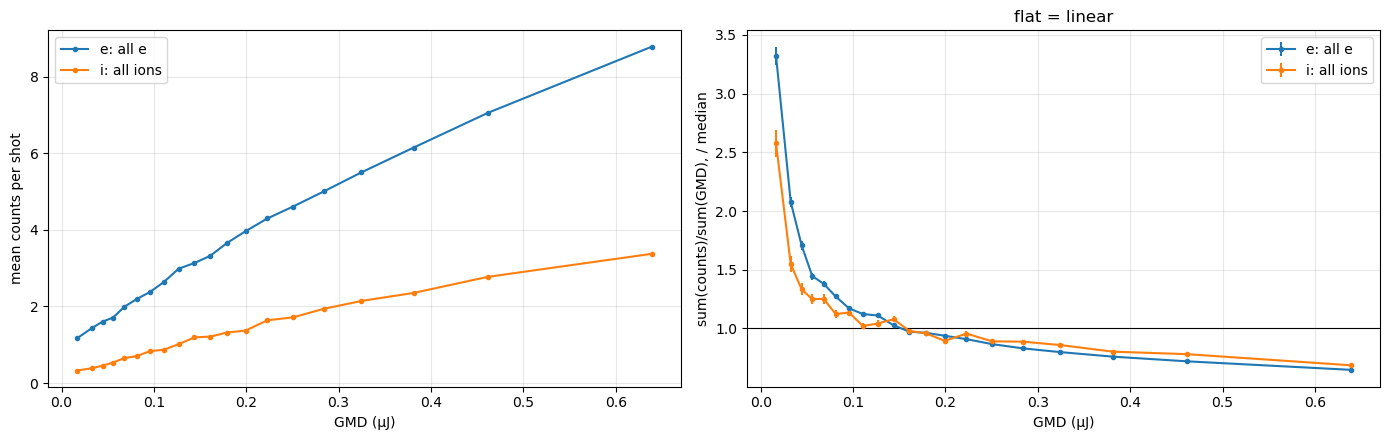

In [17]:
if tofs_e is not None:
    windows = {**{f"e: {k}": (tofs_e, v) for k, v in E_TOF_WINDOWS.items()},
               **{f"i: {k}": (tofs_i, v) for k, v in I_TOF_WINDOWS.items()}}
    counts = {name: ((t >= lo) & (t < hi) & (t > 0)).sum(axis=-1) for name, (t, (lo, hi)) in windows.items()}

    g = gmd[shot]
    gmd_edges = np.percentile(g, np.linspace(1, 99, N_GMD_BINS + 1))
    gbin = np.digitize(g, gmd_edges) - 1
    inb = (gbin >= 0) & (gbin < N_GMD_BINS)
    gmd_cent = np.bincount(gbin[inb], g[inb], N_GMD_BINS) / np.bincount(gbin[inb], minlength=N_GMD_BINS)

    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, c in counts.items():
        cs = c[shot].astype(float)
        sum_c = np.bincount(gbin[inb], cs[inb], N_GMD_BINS)
        sum_g = np.bincount(gbin[inb], g[inb], N_GMD_BINS)
        n_bin = np.bincount(gbin[inb], minlength=N_GMD_BINS)
        yield_ = sum_c / sum_g                                   # counts per µJ in each GMD bin
        err = np.sqrt(sum_c) / sum_g                             # Poisson
        axs[0].plot(gmd_cent, sum_c / n_bin, ".-", label=name)
        axs[1].errorbar(gmd_cent, yield_ / np.nanmedian(yield_), err / np.nanmedian(yield_), fmt=".-", label=name)
    axs[0].set(xlabel="GMD (µJ)", ylabel="mean counts per shot")
    axs[0].legend()
    axs[1].axhline(1, color="k", lw=0.8)
    axs[1].set(xlabel="GMD (µJ)", ylabel="sum(counts)/sum(GMD), / median", title="flat = linear")
    axs[1].legend()
    fig.tight_layout()
    plt.show()

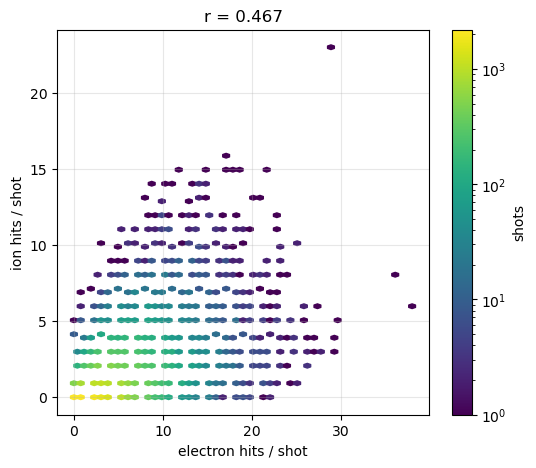

In [18]:
# Electron vs ion counts per shot
if tofs_e is not None:
    fig, ax = plt.subplots(figsize=(6, 5))
    hb = ax.hexbin(n_e[shot], n_i[shot], gridsize=(min(cap_e, 50), min(cap_i, 60)), bins="log", mincnt=1)
    fig.colorbar(hb, ax=ax, label="shots")
    ax.set(xlabel="electron hits / shot", ylabel="ion hits / shot",
           title=f"r = {np.corrcoef(n_e[shot], n_i[shot])[0, 1]:.3f}")
    plt.show()

## 7. Correlations and stability

`per_shot` collects every per-shot observable available, each `(n_trains, n_bunches)` — add your own
(e.g. a TOF window, or `vls_width`). Left: Pearson correlation of each pair over the shots where both are
finite. Right: per-train GMD-normalised yields (`sum(x)/sum(GMD)` over the train's shots, relative to the
run median) — drifts show up here.

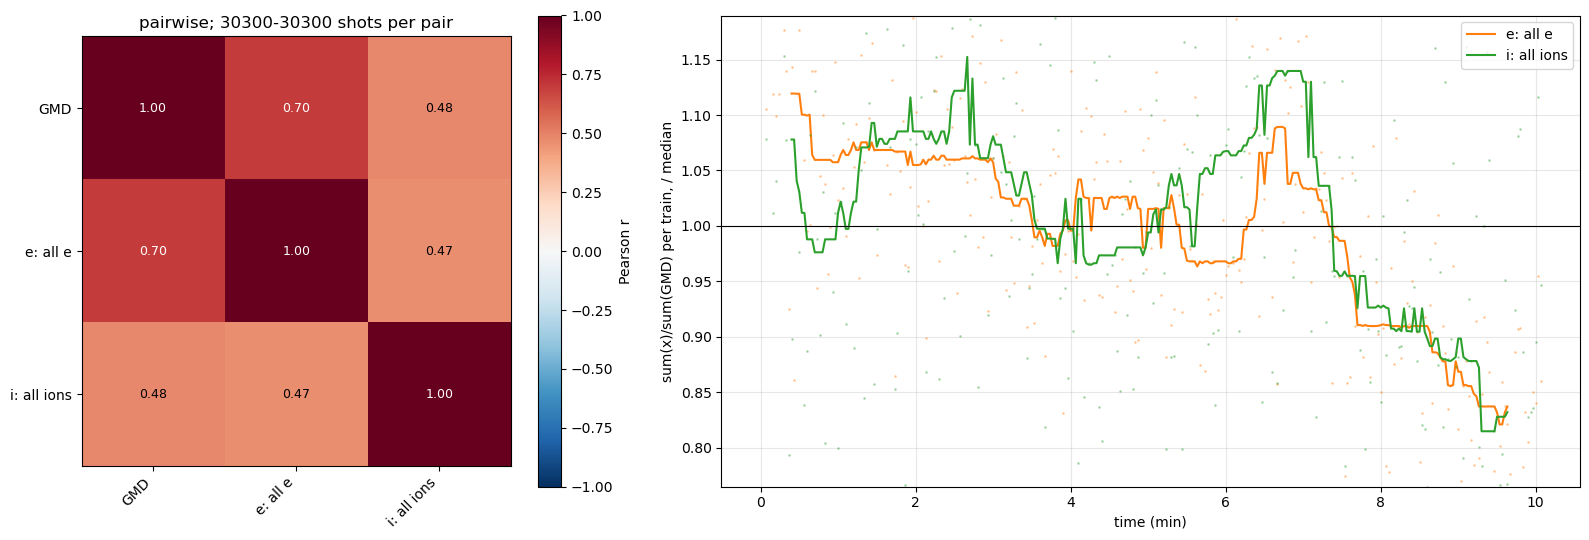

In [19]:
per_shot = {"GMD": gmd}
if tofs_e is not None:
    per_shot.update(counts)
if vls is not None:
    per_shot.update({"VLS integral": vls_sum, "VLS COM": vls_com})

names = list(per_shot)
corr = np.full((len(names), len(names)), np.nan)      # pairwise: shots where both are finite
n_pair = np.zeros_like(corr, dtype=int)
for i, a in enumerate(names):
    for j, b in enumerate(names):
        m = shot & np.isfinite(per_shot[a]) & np.isfinite(per_shot[b])
        n_pair[i, j] = m.sum()
        if m.sum() > 10:
            corr[i, j] = np.corrcoef(per_shot[a][m], per_shot[b][m])[0, 1]

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
im = axs[0].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axs[0].set_xticks(range(len(names)), names, rotation=45, ha="right")
axs[0].set_yticks(range(len(names)), names)
axs[0].grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        axs[0].text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="w" if abs(corr[i, j]) > 0.6 else "k")
fig.colorbar(im, ax=axs[0], label="Pearson r")
axs[0].set_title(f"pairwise; {n_pair.min()}-{n_pair.max()} shots per pair")

# yields use the shots where GMD and the observable are finite (COM is not a yield)
all_y = []
for k_col, name in enumerate(names):
    if name in ("GMD", "VLS COM"):
        continue
    use = shot & np.isfinite(per_shot[name])
    y_train = np.where(use, per_shot[name], 0).sum(axis=1) / np.where(use, gmd, 0).sum(axis=1)
    y_train /= np.nanmedian(y_train)
    axs[1].plot(t_min, y_train, ".", ms=2, alpha=0.3, color=f"C{k_col}")
    k = 25                                                    # rolling median over k trains
    if len(y_train) > k:
        roll = np.array([np.nanmedian(y_train[i:i + k]) for i in range(len(y_train) - k)])
        axs[1].plot(t_min[k // 2:k // 2 + len(roll)], roll, lw=1.5, color=f"C{k_col}", label=name)
        all_y.append(roll)
axs[1].axhline(1, color="k", lw=0.8)
axs[1].set(xlabel="time (min)", ylabel="sum(x)/sum(GMD) per train, / median")
if all_y:
    lo, hi = np.nanpercentile(np.concatenate(all_y), [0.5, 99.5])
    axs[1].set_ylim(min(lo, 0.9) - 0.05, max(hi, 1.1) + 0.05)
    axs[1].legend(loc="upper right")
fig.tight_layout()
plt.show()